In [5]:
# Step 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [6]:
# Step 2: Load dataset
data = pd.read_csv("C:/Users/prath/Downloads/ML_PRAC/uber.csv")

In [7]:
# Step 3: Display first five records
print("First Five Records:")
print(data.head())

First Five Records:
   Unnamed: 0                  key  fare_amount          pickup_datetime  \
0    24238194  2015-05-07 19:52:06          7.5  2015-05-07 19:52:06 UTC   
1    27835199  2009-07-17 20:04:56          7.7  2009-07-17 20:04:56 UTC   
2    44984355  2009-08-24 21:45:00         12.9  2009-08-24 21:45:00 UTC   
3    25894730   2009-06-26 8:22:21          5.3  2009-06-26 08:22:21 UTC   
4    17610152  2014-08-28 17:47:00         16.0  2014-08-28 17:47:00 UTC   

   pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude  \
0        -73.999817        40.738354         -73.999512         40.723217   
1        -73.994355        40.728225         -73.994710         40.750325   
2        -74.005043        40.740770         -73.962565         40.772647   
3        -73.976124        40.790844         -73.965316         40.803349   
4        -73.925023        40.744085         -73.973082         40.761247   

   passenger_count  
0                1  
1                1

In [8]:
# Step 4: Dataset information
print("\nDataset Information:")
data.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [9]:
# Step 5: Statistical description
print("\nStatistical Description:")
print(data.describe())


Statistical Description:
         Unnamed: 0    fare_amount  pickup_longitude  pickup_latitude  \
count  2.000000e+05  200000.000000     200000.000000    200000.000000   
mean   2.771250e+07      11.359955        -72.527638        39.935885   
std    1.601382e+07       9.901776         11.437787         7.720539   
min    1.000000e+00     -52.000000      -1340.648410       -74.015515   
25%    1.382535e+07       6.000000        -73.992065        40.734796   
50%    2.774550e+07       8.500000        -73.981823        40.752592   
75%    4.155530e+07      12.500000        -73.967153        40.767158   
max    5.542357e+07     499.000000         57.418457      1644.421482   

       dropoff_longitude  dropoff_latitude  passenger_count  
count      199999.000000     199999.000000    200000.000000  
mean          -72.525292         39.923890         1.684535  
std            13.117408          6.794829         1.385997  
min         -3356.666300       -881.985513         0.000000  
25%   

In [10]:
# Step 6: Check missing values
print("\nMissing Values:")
print(data.isnull().sum())


Missing Values:
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [11]:
# Step 7: Remove missing values
data = data.dropna()

In [12]:
# Step 8: Remove unnecessary columns
if 'Unnamed: 0' in data.columns:
    data.drop('Unnamed: 0', axis=1, inplace=True)

if 'key' in data.columns:
    data.drop('key', axis=1, inplace=True)

In [13]:
# Step 9: Convert pickup datetime
data['pickup_datetime'] = pd.to_datetime(
    data['pickup_datetime'],
    errors='coerce'
)

data = data.dropna(subset=['pickup_datetime'])

In [14]:
# Step 10: Extract date and time features
data['hour'] = data['pickup_datetime'].dt.hour
data['day'] = data['pickup_datetime'].dt.day
data['month'] = data['pickup_datetime'].dt.month
data['year'] = data['pickup_datetime'].dt.year
data['day_of_week'] = data['pickup_datetime'].dt.dayofweek


In [15]:
# Step 11: Remove original datetime column
data.drop('pickup_datetime', axis=1, inplace=True)

In [16]:
# Step 12: Remove invalid fare and location values
data = data[
    (data['fare_amount'] > 0) &
    (data['passenger_count'] > 0) &
    (data['pickup_latitude'].between(-90, 90)) &
    (data['dropoff_latitude'].between(-90, 90)) &
    (data['pickup_longitude'].between(-180, 180)) &
    (data['dropoff_longitude'].between(-180, 180))
]

In [17]:
# Step 13: Calculate distance using Haversine formula
def haversine(lat1, lon1, lat2, lon2):

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return 6371 * c


data['distance'] = haversine(
    data['pickup_latitude'],
    data['pickup_longitude'],
    data['dropoff_latitude'],
    data['dropoff_longitude']
)

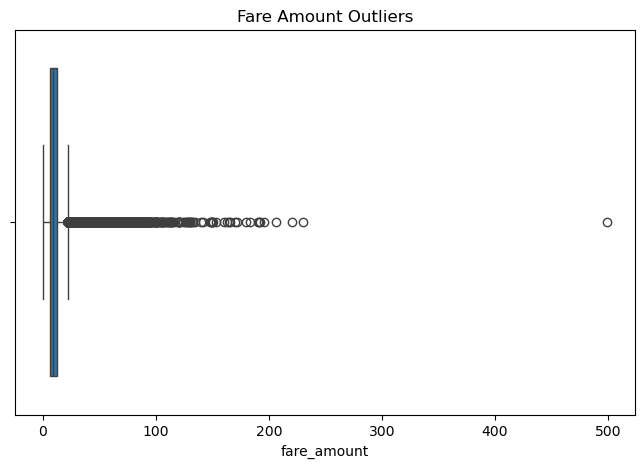

In [18]:
# Step 14: Remove zero-distance records
data = data[data['distance'] > 0]

# Step 15: Identify fare outliers using boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(x=data['fare_amount'])
plt.title("Fare Amount Outliers")
plt.show()

In [19]:
# Step 16: Remove extreme fare outliers
Q1 = data['fare_amount'].quantile(0.25)
Q3 = data['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

data = data[
    (data['fare_amount'] >= lower_limit) &
    (data['fare_amount'] <= upper_limit)
]

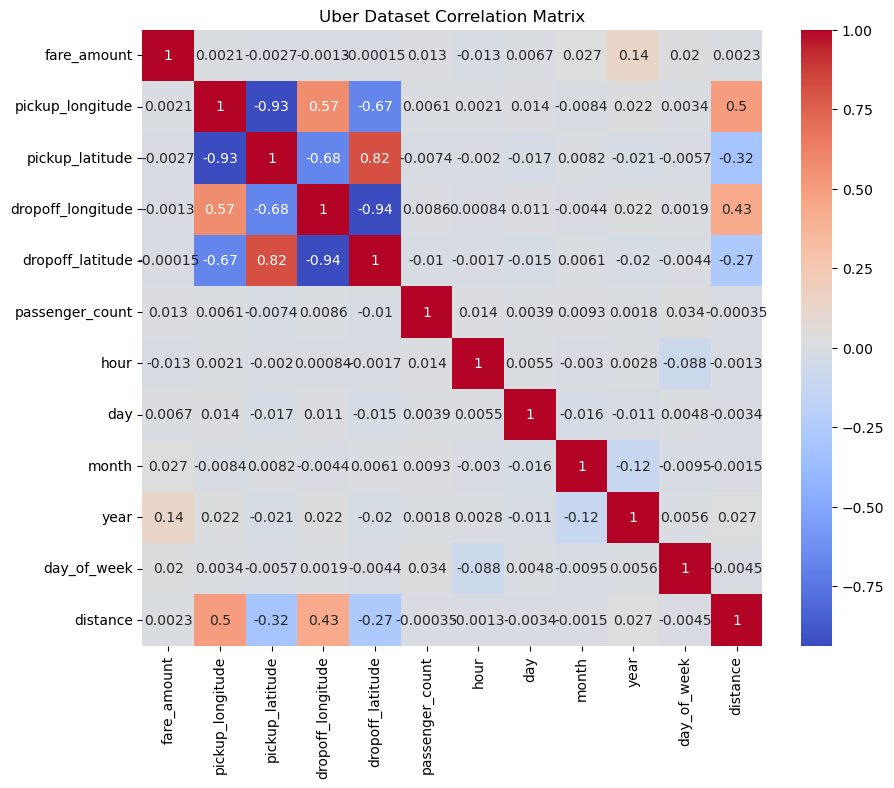

In [20]:
# Step 17: Check correlation
plt.figure(figsize=(10, 8))

sns.heatmap(
    data.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.title("Uber Dataset Correlation Matrix")
plt.show()

In [21]:
# Step 18: Separate input and output
X = data.drop('fare_amount', axis=1)
y = data['fare_amount']

In [22]:
# Step 19: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [23]:
# Step 20: Linear Regression
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

lr_r2 = r2_score(y_test, lr_pred)

lr_rmse = np.sqrt(
    mean_squared_error(y_test, lr_pred)
)

print("\nLinear Regression Results:")
print("R2 Score:", lr_r2)
print("RMSE:", lr_rmse)



Linear Regression Results:
R2 Score: 0.02207469098401338
RMSE: 4.113939012766098


In [ ]:
# Step 21: Random Forest Regression
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_r2 = r2_score(y_test, rf_pred)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred)
)

print("\nRandom Forest Regression Results:")
print("R2 Score:", rf_r2)
print("RMSE:", rf_rmse)

In [ ]:
# Step 22: Compare both models
print("\nModel Comparison")

print("Linear Regression R2:", lr_r2)
print("Random Forest R2:", rf_r2)

print("Linear Regression RMSE:", lr_rmse)
print("Random Forest RMSE:", rf_rmse)

In [ ]:
# Step 23: Visualize actual vs predicted values
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    rf_pred,
    alpha=0.5
)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")

plt.title("Actual vs Predicted Uber Fare")

plt.show()